#  Notebook 4 — Analyse croisée des trois tables
**Projet Data Mining — Investigation sur plusieurs datasets**

## Rôle de ce notebook
Les notebooks 1 à 3 ont étudié chaque table séparément. Celui-ci croise les trois (monitoring_sites, monitoring_device_operations, orchard_surveys) pour tester les pistes laissées ouvertes





## Cellule 1 — Imports et chargement


In [1]:
import os, re, itertools, warnings
from math import comb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics.pairwise import haversine_distances
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 120)
sns.set_theme(style="whitegrid")

FILES = ["monitoring_sites.csv", "monitoring_device_operations.csv", "orchard_surveys.csv"]
try:
    from google.colab import files
    if not all(os.path.exists(f) for f in FILES):
        print("Téléverse les trois fichiers :", FILES)
        files.upload()
except ImportError:
    pass

def find(name):
    for p in [name, "/mnt/user-data/uploads/" + name]:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"{name} introuvable : téléverse-le")

sites = pd.read_csv(find(FILES[0])); raw_dev = pd.read_csv(find(FILES[1])); raw_orc = pd.read_csv(find(FILES[2]))
print("sites", sites.shape, "| device_operations", raw_dev.shape, "| orchard_surveys", raw_orc.shape)

sites (64, 14) | device_operations (4994, 11) | orchard_surveys (1250, 11)


## Cellule 2 — Nettoyage compact et matrices communes


In [2]:
# ---- Nettoyage compact
sites["site_category"] = sites.site_category.str.strip().str.lower()

dev = raw_dev.drop_duplicates().copy()
dev["uptime"] = pd.to_numeric(dev.uptime_pct.astype(str).str.replace(",", ".", regex=False), errors="coerce")
dev["maintenance_type"] = dev.maintenance_type.str.strip().str.lower()
dev["ym"] = pd.to_datetime(dev.operation_start).dt.to_period("M"); dev["month"] = dev.ym.dt.month
dev["fault"] = dev.fault_code.fillna("none")
prov = dev.groupby("site_code").maintenance_provider.agg(lambda x: x.dropna().iloc[0])      # 1 fournisseur par site
dev["provider"] = dev.site_code.map(prov)
dev["device_model"] = dev.device_reference.str.extract(r"-(\d+)$")[0]

def to_num(s):
    return pd.to_numeric(s.astype(str).str.replace(",", ".", regex=False).str.replace(r"[^0-9.\-]", "", regex=True), errors="coerce")

orc = raw_orc.drop_duplicates().copy()
for c in ["orchard_area_ha", "durian_flower_density", "durian_yield_kg", "fertilizer_use_index"]:
    orc[c] = to_num(orc[c])
orc = orc.rename(columns={"durian_flower_density": "flo", "fruit_set_rate_pct": "fs", "other_pollinator_activity": "pol",
                          "durian_yield_kg": "yld", "fertilizer_use_index": "fer", "irrigation_level": "irr"})
orc.loc[orc.fs < 1, "fs"] *= 100                                                           # nouaison saisie en fraction (inférence du notebook 3)
orc["note"] = orc.agricultural_disturbance_note.str.strip().str.replace(r"\s+", " ", regex=True)
orc["ym"] = pd.to_datetime(orc.survey_period).dt.to_period("M"); orc["m"] = orc.ym.dt.month; orc["yha"] = orc.yld / orc.orchard_area_ha

# Nouaison non expliquée : résidu du modèle du notebook 3 (mois + fleurs + pollinisateurs + engrais + irrigation)
Xm = np.column_stack([np.ones(len(orc)), pd.get_dummies(orc.m, drop_first=True).astype(float).to_numpy(), orc.flo, orc.pol, orc.fer, orc.irr])
beta = np.linalg.lstsq(Xm, orc.fs.values, rcond=None)[0]; orc["res"] = orc.fs - Xm @ beta

# Matrices 78 mois x sites ; "d" = écart au profil mensuel PROPRE du site (désaisonnalisation)
def piv(df, col): return df.pivot(index="ym", columns="site_code", values=col)
def deseason(M): return M - M.groupby(M.index.month).transform("mean")
Q, U = piv(dev, "acoustic_quality"), piv(dev, "uptime"); Qd, Ud = deseason(Q), deseason(U)
R, FS, FL, PO = piv(orc, "res"), piv(orc, "fs"), piv(orc, "flo"), piv(orc, "pol"); Rd, FSd, FLd = deseason(R), deseason(FS), deseason(FL)

SPECIAL = ["AVL-TRP", "KNT-CHP"]; NORMAL = [c for c in Q.columns if c not in SPECIAL]; ORCH = list(R.columns)
reg = sites.set_index("site_code").region
print("Appareils :", len(dev), "lignes | vergers :", len(orc), "lignes | matrices :", Q.shape, "et", R.shape)

Appareils : 4992 lignes | vergers : 1248 lignes | matrices : (78, 64) et (78, 16)


## Cellule 3 — Jointure des trois tables


In [3]:
panel = orc.merge(dev[["site_code", "ym", "uptime", "acoustic_quality", "maintenance_type", "fault", "provider", "device_model"]],
                  on=["site_code", "ym"], how="left", validate="one_to_one")
print("Lignes du panel (verger x mois) :", len(panel), "| sans mesure d'appareil :", panel.acoustic_quality.isna().sum())
print("Vergers présents dans la table des sites :", set(ORCH) <= set(sites.site_code), "| même période :", Q.index.equals(R.index))
print("\nTypes de maintenance dans les mois de verger :"); print(panel.maintenance_type.value_counts())
print("\nMois de verger avec une note ET une intervention d'appareil :", ((panel.note.notna()) & (panel.maintenance_type != "routine inspection")).sum())

meta = pd.DataFrame({"fournisseur": prov, "modèle": dev.drop_duplicates("site_code").set_index("site_code").device_model}).loc[ORCH]
print("\nFournisseur x modèle pour les 16 vergers :"); print(pd.crosstab(meta["fournisseur"], meta["modèle"]))
panel.head(3)

Lignes du panel (verger x mois) : 1248 | sans mesure d'appareil : 0
Vergers présents dans la table des sites : True | même période : True

Types de maintenance dans les mois de verger :
maintenance_type
routine inspection        1188
corrective maintenance      34
sensor replacement          26
Name: count, dtype: int64

Mois de verger avec une note ET une intervention d'appareil : 0

Fournisseur x modèle pour les 16 vergers :
modèle         1  2  3
fournisseur           
ECO-SERVICE-1  0  2  2
ECO-SERVICE-2  2  1  2
ECO-SERVICE-3  2  0  2
ECO-SERVICE-4  1  0  2


,orchard_survey_id,site_code,survey_period,orchard_area_ha,flo,fs,yld,pol,fer,irr,agricultural_disturbance_note,note,ym,m,yha,res,uptime,acoustic_quality,maintenance_type,fault,provider,device_model
0,ORC-0000001,AVL-MAR,2019-01-01,24.1,40.3,34.7,20400.8,55.2,27.1,38.4,NaN,NaN,2019-01,1,846.506224,-10.672942,100.0,70.9,routine inspection,none,ECO-SERVICE-1,2
1,ORC-0000002,AVL-MAR,2019-02-01,24.1,33.8,41.6,17712.7,63.8,44.2,41.6,NaN,NaN,2019-02,2,734.966805,-7.211750,100.0,72.7,routine inspection,none,ECO-SERVICE-1,2
2,ORC-0000003,AVL-MAR,2019-03-01,24.1,55.1,57.3,28900.5,77.4,35.2,45.6,NaN,NaN,2019-03,3,1199.190871,-1.781648,97.5,76.0,routine inspection,none,ECO-SERVICE-1,2


## Cellule 4 — Les noms de site cachent-ils un indice ?


In [4]:
# Les noms de site contiennent-ils un indice caché ?
sites["is_core"] = np.arange(len(sites)) < 8
clean = sites.site_name.str.lower().str.replace(r"\b(monitoring|site)\b", "", regex=True).str.strip()
sites["tokens"] = clean.str.split()
sites["name_cave"] = sites.tokens.map(lambda t: any(w in t for w in ["cavern", "cave", "karst"]))
sites["name_orchard"] = sites.tokens.map(lambda t: "orchard" in t)

print("Noms des 8 premiers sites :"); print(sites.loc[sites.is_core, ["site_code", "site_name", "site_category"]].to_string(index=False))
for label, mask in [("8 premiers sites", sites.is_core), ("56 autres sites", ~sites.is_core)]:
    sub = sites[mask]
    print(f"\n{label} : nom contient cavern/cave/karst -> {sub.name_cave.sum()} sites dont {int((sub.name_cave & (sub.site_category == 'cave monitoring')).sum())} classés caverne"
          f" | nom contient 'orchard' -> {sub.name_orchard.sum()} dont {int((sub.name_orchard & (sub.site_category == 'orchard monitoring')).sum())} classés verger")

rest = sites[~sites.is_core]
for kw, cat in [("name_cave", "cave monitoring"), ("name_orchard", "orchard monitoring")]:
    tab = pd.crosstab(rest[kw], rest.site_category == cat)
    print(f"\nTest exact de Fisher (56 sites) {kw} ~ catégorie '{cat}' : p =", round(stats.fisher_exact(tab.reindex(index=[False, True], columns=[False, True], fill_value=0))[1], 3))

print("\nSites aux noms trompeurs (mot caverne/verger mais autre catégorie) :")
print(rest[(rest.name_cave & (rest.site_category != "cave monitoring")) | (rest.name_orchard & (rest.site_category != "orchard monitoring"))][["site_code", "site_name", "site_category"]].to_string(index=False))

# TF-IDF : mots les plus caractéristiques de chaque catégorie, sur les 56 sites
docs = rest.groupby("site_category").tokens.apply(lambda s: " ".join(w for t in s for w in t))
tf = TfidfVectorizer(); Xt = tf.fit_transform(docs); terms = np.array(tf.get_feature_names_out())
print("\nTop 5 TF-IDF par catégorie (56 sites) :")
for i, cat in enumerate(docs.index): print(f"  {cat:<20}", terms[np.argsort(-Xt[i].toarray()[0])[:5]].tolist())

Noms des 8 premiers sites :
site_code                      site_name      site_category
  KNT-KES Kestrel Cavern Monitoring Site    cave monitoring
  KNT-LUM        Luma Karst Reserve Site    cave monitoring
  KNT-SEN          Senna Ridge Cave Site    cave monitoring
  AVL-MAR       Marula East Orchard Site orchard monitoring
  AVL-VEL       Velin Basin Orchard Site orchard monitoring
  AVL-ORR     Orra Research Orchard Site orchard monitoring
  TMB-NAC          Nacre Coast Cave Site    cave monitoring
  TMB-PEL  Pelagos Grove Monitoring Site habitat monitoring

8 premiers sites : nom contient cavern/cave/karst -> 4 sites dont 4 classés caverne | nom contient 'orchard' -> 3 dont 3 classés verger

56 autres sites : nom contient cavern/cave/karst -> 3 sites dont 0 classés caverne | nom contient 'orchard' -> 3 dont 0 classés verger

Test exact de Fisher (56 sites) name_cave ~ catégorie 'cave monitoring' : p = 1.0

Test exact de Fisher (56 sites) name_orchard ~ catégorie 'orchard monitorin

### Interprétation (cellule 4)
ceci confirme et renforce l'hypothèse du notebook 1 : les 8 premiers sites ont une origine distincte (coordonnées arrondies, noms soignés), les 56 autres sont des sites générés par gabarit. C'est un indice de données construites, pas un secret écologique. On n'utilise donc pas les noms comme source d'information.

## Cellule 5 — Dossier des vergers : 3 tables réunies


Variance expliquée PCA : [0.41 0.35]
            PC1   PC2
fs         0.42 -0.15
pol        0.36 -0.21
flo        0.39  0.17
yha        0.41 -0.17
res        0.38 -0.18
notes     -0.19  0.12
q_mean    -0.16 -0.44
q_std      0.09  0.46
u_mean    -0.19 -0.42
n_fault    0.18  0.44
elev       0.02  0.19
log_dcave -0.29  0.14

Top 5 Isolation Forest : ['AVL-TRP', 'TMB-BRC', 'AVL-FNQ', 'TMB-HQL', 'AVL-GRB']
Top 5 LOF              : ['AVL-TRP', 'AVL-FNQ', 'TMB-BRC', 'TMB-HQL', 'AVL-GRB']

Dossier des vergers clés (3 tables réunies) :
             fs   pol   flo     yha  res  notes  q_mean  q_std  u_mean  n_fault   elev  log_dcave
site_code                                                                                        
TMB-BRC    65.8  70.0  67.8  1261.3  6.2      0    78.6    7.7    92.7        2  220.6        2.7
AVL-TRP    55.0  58.5  69.0  1066.8  0.2      0    68.6   13.8    77.9       28  237.0        6.5
AVL-FNQ    47.8  54.4  60.4   919.8 -2.8     16    76.4    9.8    94.5     

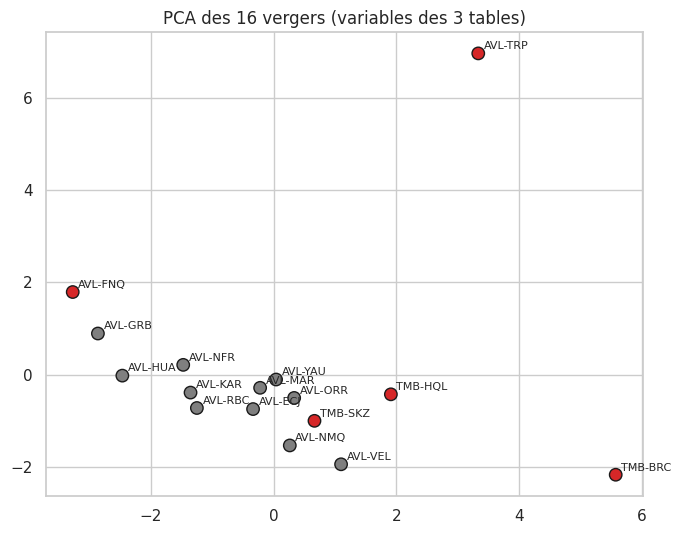

In [5]:
R_EARTH = 6371.0
S = sites.reset_index(drop=True); Dk = haversine_distances(np.radians(S[["latitude", "longitude"]].to_numpy())) * R_EARTH
cave_idx = S.index[S.site_category == "cave monitoring"]
dist_cave = pd.Series(Dk[:, cave_idx].min(axis=1), index=S.site_code)

OF = orc.groupby("site_code").agg(fs=("fs", "mean"), pol=("pol", "mean"), flo=("flo", "mean"), yha=("yha", "mean"), res=("res", "mean"), notes=("note", lambda x: x.notna().sum()))
OF["q_mean"] = Q[ORCH].mean(); OF["q_std"] = Q[ORCH].std(); OF["u_mean"] = U[ORCH].mean()
OF["n_fault"] = dev[dev.site_code.isin(ORCH)].groupby("site_code").fault.apply(lambda x: (x != "none").sum())
OF["elev"] = sites.set_index("site_code").elevation_m.loc[ORCH]; OF["log_dcave"] = np.log(dist_cave.loc[ORCH])
cols = ["fs", "pol", "flo", "yha", "res", "notes", "q_mean", "q_std", "u_mean", "n_fault", "elev", "log_dcave"]
Z = StandardScaler().fit_transform(OF[cols])

iso = IsolationForest(n_estimators=300, contamination=0.2, random_state=0).fit(Z); OF["iso"] = -iso.score_samples(Z)
lof = LocalOutlierFactor(n_neighbors=4).fit(Z); OF["lof"] = -lof.negative_outlier_factor_
pca = PCA(2, random_state=0).fit(Z); XY = pca.transform(Z)
print("Variance expliquée PCA :", pca.explained_variance_ratio_.round(2))
print(pd.DataFrame(pca.components_.T, index=cols, columns=["PC1", "PC2"]).round(2))
print("\nTop 5 Isolation Forest :", OF.nlargest(5, "iso").index.tolist()); print("Top 5 LOF              :", OF.nlargest(5, "lof").index.tolist())

KEY = ["TMB-BRC", "AVL-TRP", "AVL-FNQ", "TMB-HQL", "TMB-SKZ"]
print("\nDossier des vergers clés (3 tables réunies) :"); print(OF.loc[KEY, cols].round(1))
fig, ax = plt.subplots(figsize=(7, 5.5)); ax.scatter(XY[:, 0], XY[:, 1], c=np.where(OF.index.isin(KEY), "#d62728", "#7f7f7f"), s=80, edgecolor="k")
for i, sc in enumerate(OF.index): ax.annotate(sc, XY[i], fontsize=8, xytext=(4, 3), textcoords="offset points")
ax.set_title("PCA des 16 vergers (variables des 3 tables)"); plt.tight_layout(); plt.show()

### Interprétation (cellule 5)


 quand on regarde toutes les tables à la fois, les mêmes sites ressortent que dans les analyses séparées : la structure est « un petit nombre de sites à part, tous les autres homogènes ». Cela renforce les résultats des notebooks précédents.

## Cellule 6 — Corrélations entre appareils et vergers


Spearman appareil ~ verger (16 vergers) :
           fs   res   flo   pol   yha
q_mean  -0.09  0.01 -0.49  0.15 -0.04
u_mean  -0.16 -0.12 -0.57 -0.11 -0.15
n_fault  0.01  0.03  0.53 -0.14 -0.00
p :
           fs   res   flo   pol   yha
q_mean   0.73  0.97  0.06  0.58  0.90
u_mean   0.55  0.65  0.02  0.67  0.58
n_fault  0.97  0.92  0.04  0.61  0.99

Sans AVL-TRP (15 vergers) :
           fs   res   flo   pol   yha
q_mean  -0.04  0.08 -0.38  0.15  0.04
u_mean  -0.11 -0.09 -0.48 -0.15 -0.10
n_fault -0.05 -0.02  0.42 -0.13 -0.07
p :
           fs   res   flo   pol   yha
q_mean   0.90  0.77  0.16  0.59  0.90
u_mean   0.69  0.75  0.07  0.58  0.72
n_fault  0.85  0.94  0.12  0.65  0.80

Plus petite p-valeur observée : 0.022 sur 15 tests -> seuil indicatif : 0.06 | corrigée (Bonferroni) : 0.327


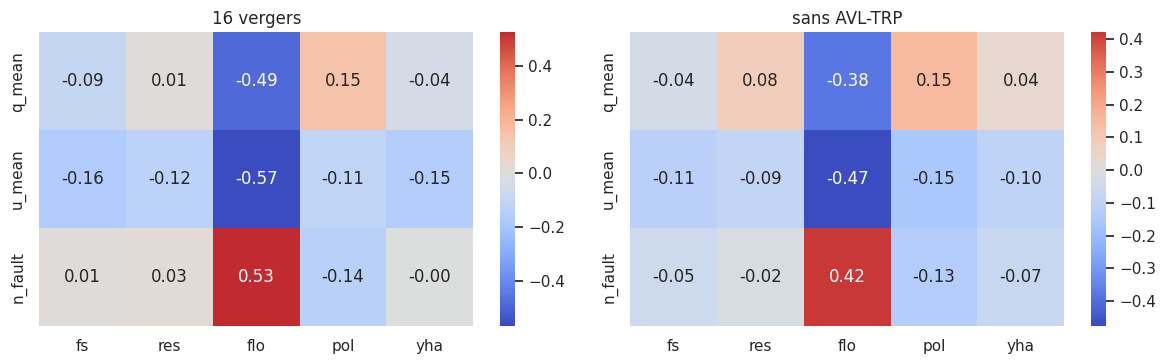

In [8]:
dev_vars = ["q_mean", "u_mean", "n_fault"]; orc_vars = ["fs", "res", "flo", "pol", "yha"]
def table(df):
    out = pd.DataFrame(index=dev_vars, columns=orc_vars, dtype=float); pv = out.copy()
    for a in dev_vars:
        for b in orc_vars:
            r, p = stats.spearmanr(df[a], df[b]); out.loc[a, b] = r; pv.loc[a, b] = p
    return out, pv
r_all, p_all = table(OF); r_no, p_no = table(OF.drop("AVL-TRP"))
print("Spearman appareil ~ verger (16 vergers) :"); print(r_all.round(2)); print("p :"); print(p_all.round(2))
print("\nSans AVL-TRP (15 vergers) :"); print(r_no.round(2)); print("p :"); print(p_no.round(2))
p_min = p_all.min().min()

print("\nPlus petite p-valeur observée :", round(p_min, 3),
      "sur", p_all.size, "tests",
      "-> seuil indicatif :", round(1 / (p_all.size + 1), 2),
      "| corrigée (Bonferroni) :", round(min(1, p_min * p_all.size), 3))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.heatmap(r_all, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[0]); ax[0].set_title("16 vergers")
sns.heatmap(r_no, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1]); ax[1].set_title("sans AVL-TRP")
plt.tight_layout(); plt.show()

### Interprétation (cellule 6)
aucun lien appareil ↔ verger établi.** L'unique « signal » repose sur AVL-TRP seul (le verger le plus fleuri a aussi les appareils les plus défaillants) : c'est la même coïncidence déjà notée, pas une relation générale. Un verger qui compte 1/16 des points ne peut pas fonder une corrélation.

## Cellule 7 — Signature commune : fournisseur et modèle d'appareil


In [9]:
sig = pd.DataFrame({"fournisseur": prov, "modèle": dev.drop_duplicates("site_code").set_index("site_code").device_model})
sig["combo"] = sig.fournisseur.str[-1] + "/" + sig["modèle"]
EXC = ["AVL-TRP", "KNT-CHP", "TMB-BRC"]       # sites ressortant des tests (notebooks 2 et 3), choisis SANS regarder fournisseur ni modèle
print("Les 3 sites exceptionnels :"); print(sig.loc[EXC])
print("\nSites partageant la combinaison fournisseur ECO-SERVICE-1 + modèle 3 :", sig.index[sig.combo == "1/3"].tolist())

N = len(sig); sizes = sig.combo.value_counts()
p_same_combo = sum(comb(n, 3) for n in sizes) / comb(N, 3)
print("\nP(3 sites tirés au hasard partagent la même combinaison fournisseur x modèle, quelle qu'elle soit) = %.4f" % p_same_combo)
print("P(les 3 sont exactement dans {ECO-SERVICE-1 + modèle 3}) = %.5f  <- TROMPEUR : ce groupe a été choisi en regardant TRP et CHP (circulaire)" % (comb(6, 3) / comb(N, 3)))
print("P honnête (réplication hors échantillon) : TRP et CHP définissent le groupe (6 sites) ; BRC y tombe par hasard avec p = 4/62 = %.3f" % (4 / 62))

n3 = (sig["modèle"] == "3").sum()
print("\nTous les sites exceptionnels ont-ils le modèle 3 ? :", (sig.loc[EXC + ["AVL-FNQ"], "modèle"] == "3").all(), "| P(4 sites au hasard tous en modèle 3) = %.4f" % (comb(n3, 4) / comb(N, 4)))
print("Les 6 sites ECO-SERVICE-1 + modèle 3 :")
g = sig.index[sig.combo == "1/3"]
tab = pd.DataFrame({"catégorie": sites.set_index("site_code").loc[g, "site_category"], "région": reg.loc[g].str[:8],
                    "pannes": dev[dev.site_code.isin(g)].groupby("site_code").fault.apply(lambda x: (x != "none").sum())})
dflo = (orc.flo - orc.groupby("m").flo.transform("mean")).groupby(orc.site_code).mean()      # écart de fleurs au mois moyen de la flotte
tab["résidu nouaison"] = OF.res.reindex(g).round(1); tab["écart fleurs"] = dflo.reindex(g).round(1); print(tab)

# Quels autres attributs partagent les 3 sites ? (chemins de décision explorés : correction nécessaire)
S2 = sites.set_index("site_code").loc[EXC, ["region", "site_category", "habitat_category", "programme_start_date", "elevation_m"]]
print("\nAttributs des 3 sites :"); print(S2)
print("Attributs partagés par les 3 :", [c for c in S2.columns if S2[c].nunique() == 1] or "aucun")

# Test exact par permutation sur les 16 vergers : la paire {BRC, TRP} est-elle exceptionnelle ?
rows = []
for v, lab in [(OF.res, "nouaison non expliquée"), (dflo.reindex(ORCH), "écart de fleurs (au mois moyen)"), (OF.fs, "nouaison"), (OF.pol, "pollinisateurs")]:
    pairs = np.array([v.loc[list(c)].mean() for c in itertools.combinations(ORCH, 2)]); obs = v.loc[["TMB-BRC", "AVL-TRP"]].mean()
    rows.append((lab, round(obs, 2), round((pairs >= obs - 1e-9).mean(), 4), round(min(1, (pairs >= obs - 1e-9).mean() * 4), 3)))
print("\nPaire {TMB-BRC, AVL-TRP} vs les 120 paires possibles de vergers :"); print(pd.DataFrame(rows, columns=["variable", "moyenne de la paire", "p exact", "p corrigé (x4)"]).to_string(index=False))

Les 3 sites exceptionnels :
             fournisseur modèle combo
site_code                            
AVL-TRP    ECO-SERVICE-1      3   1/3
KNT-CHP    ECO-SERVICE-1      3   1/3
TMB-BRC    ECO-SERVICE-1      3   1/3

Sites partageant la combinaison fournisseur ECO-SERVICE-1 + modèle 3 : ['AVL-BVM', 'AVL-TRP', 'KNT-CHP', 'TMB-BRC', 'TMB-DLQ', 'TMB-PEL']

P(3 sites tirés au hasard partagent la même combinaison fournisseur x modèle, quelle qu'elle soit) = 0.0042
P(les 3 sont exactement dans {ECO-SERVICE-1 + modèle 3}) = 0.00048  <- TROMPEUR : ce groupe a été choisi en regardant TRP et CHP (circulaire)
P honnête (réplication hors échantillon) : TRP et CHP définissent le groupe (6 sites) ; BRC y tombe par hasard avec p = 4/62 = 0.065

Tous les sites exceptionnels ont-ils le modèle 3 ? : True | P(4 sites au hasard tous en modèle 3) = 0.0115
Les 6 sites ECO-SERVICE-1 + modèle 3 :
                    catégorie    région  pannes  résidu nouaison  écart fleurs
site_code                        

### Interprétation (cellule 7)

- C'est une **piste sérieuse mais non démontrée** : 3 des 6 sites de ce groupe sont exceptionnels, contre 3 sites sur 64 en tout, et la coïncidence résiste à une version honnête du calcul (≈ 0,4 % pour « une combinaison quelconque », 6,5 % hors échantillon).
- **Elle n'est pas conclusive** : (1) on a examiné ~7 attributs (fournisseur, modèle, région, catégorie, habitat, année de début, altitude) : multiplier 0,4 % par 7 donne ≈ 3 % ; (2) la combinaison n'est ni nécessaire ni suffisante (3 membres sur 6 sont normaux) ; (3) aucun mécanisme physique plausible ne relie le fournisseur d'un enregistreur acoustique à la nouaison ou à la floraison d'un verger.
- **Lecture raisonnable :** si un lien existe, ce serait par une cause cachée commune (par exemple, la façon dont ces sites ont été choisis ou construits dans le jeu de données), pas par l'appareil lui-même. Cela cadre avec l'indice de « données construites » (cellule 4).

## Cellule 8 — TMB-BRC ↔ TMB-NAC avec décalages


Corr(résidu de nouaison de TMB-BRC, qualité acoustique de TMB-NAC), NAC précède de k mois :
{-3: np.float64(-0.0), -2: np.float64(-0.04), -1: np.float64(0.18), 0: np.float64(-0.01), 1: np.float64(-0.2), 2: np.float64(0.11), 3: np.float64(-0.11), 4: np.float64(0.19), 5: np.float64(-0.17), 6: np.float64(0.06)} | erreur standard ~ 0.11

|r| maximal observé : 0.20 | simulé sous hasard : médiane 0.23, 95e percentile 0.35 | p = 0.67
Max |r| avec TMB-NAC pour les 15 autres vergers : médiane 0.24, max 0.32 (AVL-YAU)

Par année (2025 = 6 mois, saison haute) :
ym                            2019  2020  2021  2022  2023  2024  2025
qualité NAC                   84.3  80.3  77.7  76.5  77.1  77.3  75.5
qualité autres sites Tembara  79.6  79.3  79.6  78.8  78.0  78.2  78.5
nouaison non expliquée BRC     4.9   8.3   6.0   6.7   5.4   6.4   5.8


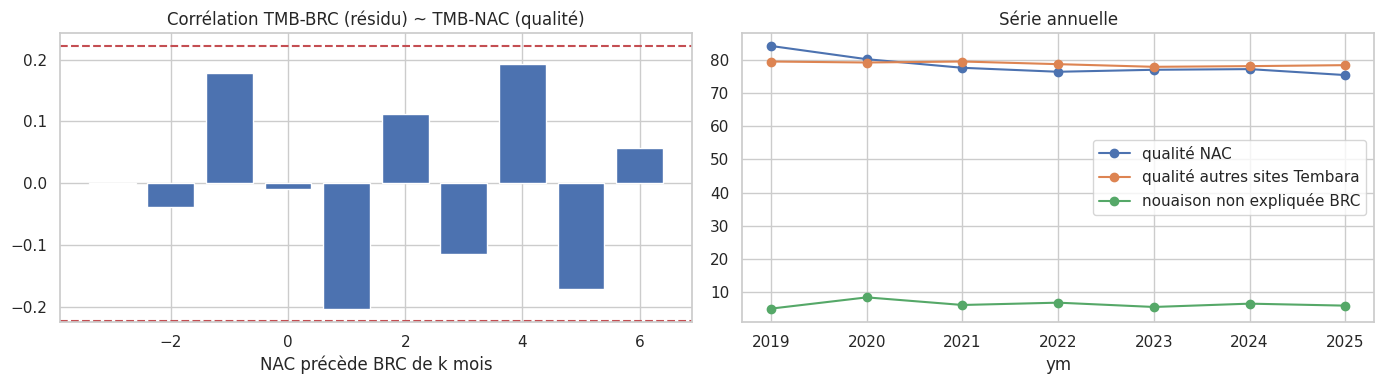

In [10]:
def lag_corr(x, y, k):          # corr(x_t, y_{t-k}) : y précède x de k mois (k < 0 : y suit x)
    a, b = (x[k:], y[:len(y) - k]) if k >= 0 else (x[:k], y[-k:])
    return np.corrcoef(a, b)[0, 1]

LAGS = range(-3, 7); n = len(Rd)
y = Qd["TMB-NAC"].values; x = Rd["TMB-BRC"].values
obs = {k: lag_corr(x, y, k) for k in LAGS}
print("Corr(résidu de nouaison de TMB-BRC, qualité acoustique de TMB-NAC), NAC précède de k mois :")
print({k: round(v, 2) for k, v in obs.items()}, "| erreur standard ~", round(1 / np.sqrt(n), 2))

# Écart-type du bruit : décalage circulaire aléatoire de la série (conserve l'autocorrélation)
rng = np.random.default_rng(0); obs_max = max(abs(v) for v in obs.values())
sims = np.array([max(abs(lag_corr(np.roll(x, int(rng.integers(6, n - 6))), y, k)) for k in LAGS) for _ in range(3000)])
print("\n|r| maximal observé : %.2f | simulé sous hasard : médiane %.2f, 95e percentile %.2f | p = %.2f" % (obs_max, np.median(sims), np.percentile(sims, 95), (1 + (sims >= obs_max).sum()) / (len(sims) + 1)))

# Groupe témoin : les 15 autres vergers face à TMB-NAC
ctrl = {oc: max(abs(lag_corr(Rd[oc].values, y, k)) for k in LAGS) for oc in ORCH if oc != "TMB-BRC"}
print("Max |r| avec TMB-NAC pour les 15 autres vergers : médiane %.2f, max %.2f (%s)" % (np.median(list(ctrl.values())), max(ctrl.values()), max(ctrl, key=ctrl.get)))

# À l'échelle annuelle
yy = pd.DataFrame({"qualité NAC": Q["TMB-NAC"].groupby(Q.index.year).mean(), "qualité autres sites Tembara": Q[[c for c in Q.columns if c.startswith("TMB") and c != "TMB-NAC"]].mean(axis=1).groupby(Q.index.year).mean(),
                   "nouaison non expliquée BRC": R["TMB-BRC"].groupby(R.index.year).mean()}).round(1)
print("\nPar année (2025 = 6 mois, saison haute) :"); print(yy.T)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(list(obs.keys()), list(obs.values())); ax[0].axhline(1.96 / np.sqrt(n), ls="--", c="r"); ax[0].axhline(-1.96 / np.sqrt(n), ls="--", c="r")
ax[0].set_xlabel("NAC précède BRC de k mois"); ax[0].set_title("Corrélation TMB-BRC (résidu) ~ TMB-NAC (qualité)")
yy.plot(marker="o", ax=ax[1]); ax[1].set_title("Série annuelle")
plt.tight_layout(); plt.show()

il n'y a aucune covariation entre TMB-NAC et TMB-BRC : ni mois par mois, ni sur 7 ans. Quand l'acoustique de la caverne se dégrade, l'avantage du verger reste identique. Cela affaiblit fortement (sans la réfuter) l'idée d'un effet de la caverne.
Limites :(1) la qualité acoustique est une mesure d'appareil, pas d'activité animale ; (2) 78 points mensuels peu puissants pour des effets faibles ; (3) la chute de TMB-NAC est surtout une année 2019 inhabituellement haute, suivie d'un plateau.

## Cellule 9 — Balayage global verger × site × décalage


Combinaisons testées : 7168 (16 vergers x 64 sites x 7 décalages)
|r| maximal observé : 0.461 | sous hasard : médiane 0.454, 95e perc. 0.510 | p (max sur toutes les combinaisons) = 0.38

Les 8 plus fortes corrélations :
 verger site acoustique  décalage      r
TMB-BRC         TMB-GWP         0 -0.461
AVL-NMQ         AVL-DER         0 -0.411
AVL-NMQ         AVL-NMQ         5 -0.410
AVL-ORR         AVL-ABG         5  0.408
AVL-GRB         AVL-BVM         5  0.402
AVL-ORR         TMB-HQL         4 -0.397
AVL-HUA         KNT-SEN         3 -0.393
AVL-VEL         AVL-VEL         6 -0.392

TMB-BRC ~ TMB-NAC, décalages 0 à 6 : [np.float64(-0.01), np.float64(-0.2), np.float64(0.11), np.float64(-0.11), np.float64(0.19), np.float64(-0.17), np.float64(0.06)]
Rang de ces corrélations parmi les 7168 : plus forte = rang 756


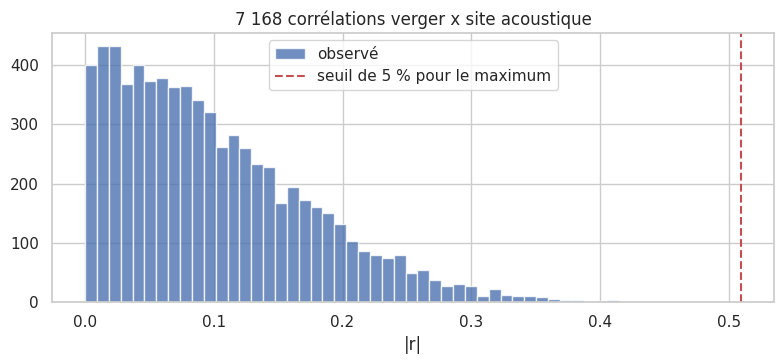

In [11]:
def zs(a): return (a - a.mean(0)) / a.std(0)
Zo, Za = zs(Rd.values), zs(Qd.values); n = len(Zo); LAGMAX = 6
def scan(Zo):
    return np.array([(Zo[k:].T @ Za[:n - k]) / (n - k) for k in range(LAGMAX + 1)])      # lags x 16 vergers x 64 sites
obs = scan(Zo); amax = np.abs(obs).max()
rng = np.random.default_rng(0); mx = []
for _ in range(300):
    shifts = rng.integers(6, n - 6, size=Zo.shape[1])
    mx.append(np.abs(scan(np.column_stack([np.roll(Zo[:, j], shifts[j]) for j in range(Zo.shape[1])]))).max())
mx = np.array(mx)
print("Combinaisons testées :", obs.size, "(16 vergers x 64 sites x 7 décalages)")
print("|r| maximal observé : %.3f | sous hasard : médiane %.3f, 95e perc. %.3f | p (max sur toutes les combinaisons) = %.2f" % (amax, np.median(mx), np.percentile(mx, 95), (1 + (mx >= amax).sum()) / (len(mx) + 1)))
idx = np.unravel_index(np.argsort(-np.abs(obs).ravel())[:8], obs.shape)
print("\nLes 8 plus fortes corrélations :")
print(pd.DataFrame({"verger": [Rd.columns[i] for _, i, _ in zip(*idx)], "site acoustique": [Q.columns[j] for _, _, j in zip(*idx)], "décalage": idx[0], "r": [round(obs[l, i, j], 3) for l, i, j in zip(*idx)]}).to_string(index=False))
i_b, j_n = list(Rd.columns).index("TMB-BRC"), list(Q.columns).index("TMB-NAC")
print("\nTMB-BRC ~ TMB-NAC, décalages 0 à 6 :", [round(obs[l, i_b, j_n], 2) for l in range(LAGMAX + 1)])
print("Rang de ces corrélations parmi les %d : plus forte = rang %d" % (obs.size, int((np.abs(obs) > np.abs(obs[:, i_b, j_n]).max()).sum()) + 1))
fig, ax = plt.subplots(figsize=(8, 3.8)); ax.hist(np.abs(obs).ravel(), bins=50, alpha=.8, label="observé"); ax.axvline(np.percentile(mx, 95), c="r", ls="--", label="seuil de 5 % pour le maximum")
ax.set_xlabel("|r|"); ax.legend(); ax.set_title("7 168 corrélations verger x site acoustique"); plt.tight_layout(); plt.show()

### Interprétation (cellule 9)
aucune relation entre une série d'appareil et une série de verger ne se distingue du bruit dans ces données, à aucun décalage de 0 à 6 mois. Une conclusion tirée de la « plus forte corrélation » aurait été une erreur de comparaisons multiples.

## Cellule 10 — Chocs communs et graphe de corrélation


In [12]:
# Chocs communs : des sites voisins varient-ils ensemble (tempête, pluie...) ? Un événement régional se verrait comme une corrélation positive entre sites de la même région.
Qn = Qd[NORMAL]; C = Qn.corr().to_numpy().copy(); same = np.array([[reg[a] == reg[b] for b in Qn.columns] for a in Qn.columns]); np.fill_diagonal(C, np.nan)
print("Corrélation moyenne des écarts acoustiques : même région %.3f | régions différentes %.3f | max %.2f" % (np.nanmean(C[same]), np.nanmean(C[~same]), np.nanmax(C)))
for nm, M in [("résidu de nouaison", Rd), ("densité de fleurs", FLd)]:
    c = M.corr().to_numpy().copy(); np.fill_diagonal(c, np.nan); print(f"Corrélation moyenne entre vergers ({nm}) : {np.nanmean(c):.3f} | max {np.nanmax(c):.2f}")

# Seuil de significativité par permutation (décalages circulaires) : max |r| sous hasard sur 62 sites
rng = np.random.default_rng(0); Zq = (Qn / Qn.std()).values; n = len(Zq); mx = []; ne = []
for _ in range(100):
    c = np.corrcoef(np.column_stack([np.roll(Zq[:, j], int(rng.integers(6, n - 6))) for j in range(Zq.shape[1])]).T).copy(); np.fill_diagonal(c, 0)
    mx.append(np.abs(c).max()); ne.append((np.abs(c) >= 0.30).sum() / 2)
thr = np.percentile(mx, 95); print("Seuil de |r| (95e percentile du maximum sous hasard) : %.2f | corrélation maximale observée : %.2f" % (thr, np.nanmax(np.abs(C))))

#
def corr_graph(th):
    G = nx.Graph(); G.add_nodes_from(Qn.columns)
    for i, a in enumerate(Qn.columns):
        for j in range(i + 1, len(Qn.columns)):
            if abs(C[i, j]) >= th: G.add_edge(a, Qn.columns[j], w=abs(C[i, j]))
    return G
G1, G2 = corr_graph(0.30), corr_graph(thr)
print("\n(a) Seuil naïf 0,30 : %d arêtes | (b) seuil contrôlé %.2f : %d arêtes" % (G1.number_of_edges(), thr, G2.number_of_edges()))
print("Arêtes attendues par pur hasard à 0,30 (décalages circulaires, 100 tirages) : moyenne %.1f, 95e percentile %.0f" % (np.mean(ne), np.percentile(ne, 95)))
n_eff = n - 12                                       # 12 moyennes mensuelles retirées par site : moins de degrés de liberté
exp_eff = len(Qn.columns) * (len(Qn.columns) - 1) / 2 * 2 * stats.t.sf(0.30 * np.sqrt((n_eff - 2) / (1 - 0.30 ** 2)), n_eff - 2)
share_same = np.mean([reg[a] == reg[b] for i, a in enumerate(Qn.columns) for b in Qn.columns[i + 1:]])
n_same = sum(reg[a] == reg[b] for a, b in G1.edges)
print("Arêtes attendues avec degrés de liberté corrigés (n - 12 = %d) : %.1f -> les %d arêtes observées sont compatibles" % (n_eff, exp_eff, G1.number_of_edges()))
print("Arêtes entre sites de la même région : %d sur %d (%.0f %%) | part attendue au hasard : %.0f %% (p binomial = %.2f, a posteriori)" % (n_same, G1.number_of_edges(), 100 * n_same / G1.number_of_edges(), 100 * share_same, stats.binom.sf(n_same - 1, G1.number_of_edges(), share_same)))
comm = nx.community.louvain_communities(G1, seed=0); lab = {s: i for i, c in enumerate(comm) for s in c}
big = [s for s in Qn.columns if G1.degree(s) > 0]
print("Louvain sur le graphe naïf :", len(comm), "communautés (", sum(len(c) > 1 for c in comm), "non triviales) | ARI vs région (sites connectés) =",
      round(adjusted_rand_score([reg[s] for s in big], [lab[s] for s in big]), 2) if len(big) > 2 else "n/a")

Corrélation moyenne des écarts acoustiques : même région 0.007 | régions différentes 0.003 | max 0.41
Corrélation moyenne entre vergers (résidu de nouaison) : 0.003 | max 0.39
Corrélation moyenne entre vergers (densité de fleurs) : 0.018 | max 0.30
Seuil de |r| (95e percentile du maximum sous hasard) : 0.51 | corrélation maximale observée : 0.45

(a) Seuil naïf 0,30 : 31 arêtes | (b) seuil contrôlé 0.51 : 0 arêtes
Arêtes attendues par pur hasard à 0,30 (décalages circulaires, 100 tirages) : moyenne 21.4, 95e percentile 28
Arêtes attendues avec degrés de liberté corrigés (n - 12 = 66) : 27.2 -> les 31 arêtes observées sont compatibles
Arêtes entre sites de la même région : 15 sur 31 (48 %) | part attendue au hasard : 32 % (p binomial = 0.04, a posteriori)
Louvain sur le graphe naïf : 33 communautés ( 13 non triviales) | ARI vs région (sites connectés) = 0.02


### Interprétation (cellule 10)
les séries de chaque site évoluent indépendamment les unes des autres, même entre sites voisins. Pas de tempête, de sécheresse ni de saison commune visible dans les écarts à la saison. Cela contraste avec la réalité(un événement météo frappe des sites voisins) et va dans le sens de données générées site par site. Un graphe construit avec un seuil naïf donne des « communautés » purement artificielles : sans seuil contrôlé, on aurait « découvert » une structure.

## Cellule 11 — Graphe spatial : composantes, communautés, centralités


Composantes connexes : [20, 22, 22] | ARI vs région : 1.0
Communautés (Louvain) : 8 de tailles [4, 7, 7, 7, 8, 10, 10, 11]

Top 5 intermédiarité :
         degré  intermédiarité  proximité
AVL-NFR      5           0.049      0.152
KNT-NNM      6           0.046      0.171
AVL-YAU      5           0.035      0.132
AVL-NMQ      6           0.034      0.149
AVL-RNY      4           0.028      0.117

Sites clés :
         degré  intermédiarité  proximité
TMB-NAC      4           0.003      0.127
TMB-BRC      7           0.022      0.147
AVL-TRP      4           0.009      0.103
KNT-CHP      3           0.000      0.092
AVL-FNQ      3           0.000      0.090
Voisins de TMB-NAC : ['TMB-VZT', 'TMB-XTD', 'TMB-BRC', 'TMB-CKU'] | voisins de TMB-BRC : ['TMB-NAC', 'TMB-PEL', 'TMB-VZT', 'TMB-XTD', 'TMB-WQL', 'TMB-HQL', 'TMB-AYQ']
Rang de intermédiarité (1 = plus central) :  {'TMB-NAC': 37, 'TMB-BRC': 9, 'AVL-TRP': 25, 'KNT-CHP': 51}


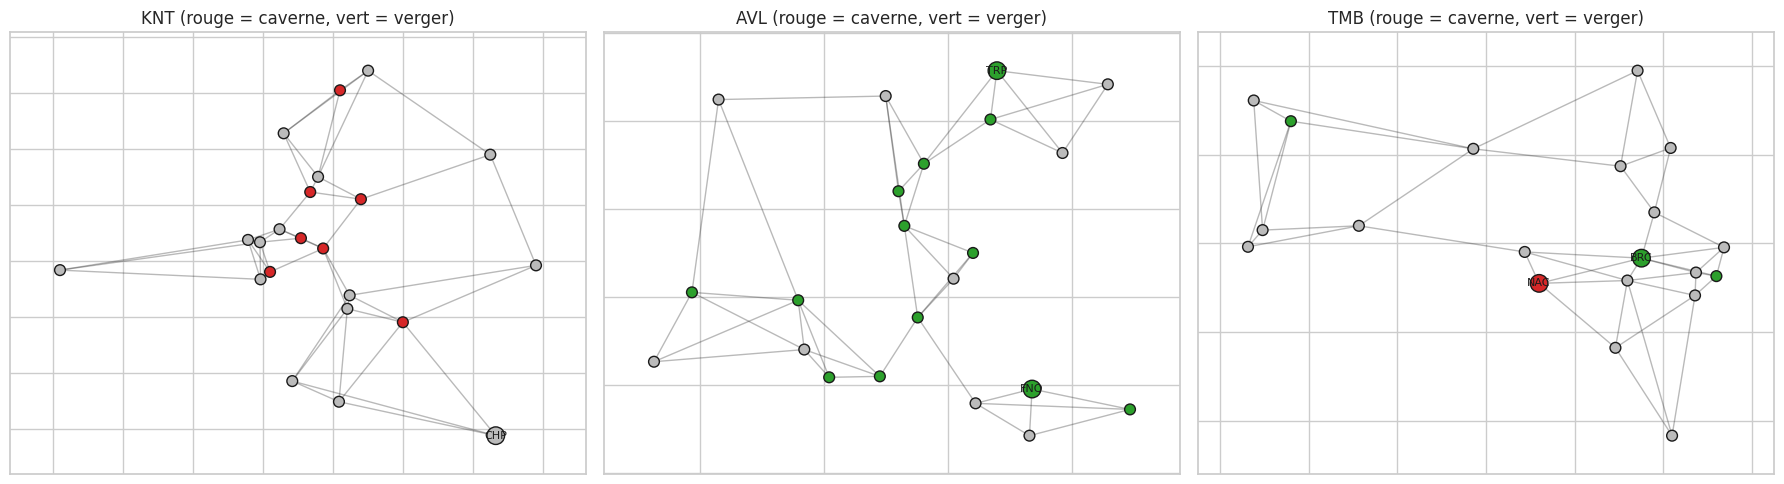

In [13]:

G = nx.Graph(); G.add_nodes_from(sites.site_code)
for i in range(len(S)):
    for j in np.argsort(Dk[i])[1:4]: G.add_edge(S.site_code[i], S.site_code[j], w=1 / (1 + Dk[i, j]))
comps = list(nx.connected_components(G)); print("Composantes connexes :", sorted(len(c) for c in comps), "| ARI vs région :",
      round(adjusted_rand_score([reg[s] for s in G], [next(i for i, c in enumerate(comps) if s in c) for s in G]), 2))
comm = nx.community.louvain_communities(G, seed=0, weight="w"); print("Communautés (Louvain) :", len(comm), "de tailles", sorted(len(c) for c in comm))
deg = pd.Series(dict(G.degree())); btw = pd.Series(nx.betweenness_centrality(G)); clo = pd.Series(nx.closeness_centrality(G))
cent = pd.DataFrame({"degré": deg, "intermédiarité": btw.round(3), "proximité": clo.round(3)})
print("\nTop 5 intermédiarité :"); print(cent.sort_values("intermédiarité", ascending=False).head(5))
print("\nSites clés :"); print(cent.loc[["TMB-NAC", "TMB-BRC", "AVL-TRP", "KNT-CHP", "AVL-FNQ"]])
print("Voisins de TMB-NAC :", list(G["TMB-NAC"]), "| voisins de TMB-BRC :", list(G["TMB-BRC"]))
print("Rang de intermédiarité (1 = plus central) : ", {s: int(btw.rank(ascending=False)[s]) for s in ["TMB-NAC", "TMB-BRC", "AVL-TRP", "KNT-CHP"]})

pos = {r.site_code: (r.longitude, r.latitude) for r in S.itertuples()}
colors = {"cave monitoring": "#d62728", "orchard monitoring": "#2ca02c", "habitat monitoring": "#bbbbbb"}
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, (z, nodes) in zip(ax, [(z, [s for s in G if s.startswith(z)]) for z in ["KNT", "AVL", "TMB"]]):
    H = G.subgraph(nodes); nx.draw_networkx_edges(H, pos, ax=a, alpha=.3)
    nx.draw_networkx_nodes(H, pos, node_color=[colors[S.set_index("site_code").site_category[s]] for s in H], node_size=[160 if s in ["TMB-NAC", "TMB-BRC", "AVL-TRP", "KNT-CHP", "AVL-FNQ"] else 60 for s in H], ax=a, edgecolors="k")
    nx.draw_networkx_labels(H, pos, labels={s: s[-3:] for s in H if s in ["TMB-NAC", "TMB-BRC", "AVL-TRP", "KNT-CHP", "AVL-FNQ"]}, font_size=8, ax=a)
    a.set_title(z + " (rouge = caverne, vert = verger)")
plt.tight_layout(); plt.show()

### Interprétation (cellule 11)
la position dans le réseau n'explique pas le caractère particulier des sites. TMB-BRC est un peu plus connecté que la moyenne, mais cela suit simplement la densité locale de sites à Tembara, sans rapport avec sa nouaison. Aucun des sites exceptionnels n'occupe de position de « pivot ».

## Cellule 12 — Décalage saisonnier acoustique ↔ vergers


In [14]:
# Profils saisonniers : l'acoustique précède-t-elle la floraison / la nouaison ? (12 points par région : à lire avec prudence)
QN = Q[NORMAL]; out = []
for z in ["AVL", "TMB"]:
    qa = QN[[c for c in QN.columns if c.startswith(z)]].groupby(QN.index.month).mean().mean(axis=1).values
    for v, lab in [("fs", "nouaison"), ("flo", "fleurs")]:
        prof = orc[orc.site_code.str.startswith(z)].groupby("m")[v].mean().values
        cc = {k: np.corrcoef(np.roll(qa, k), prof)[0, 1] for k in range(12)}
        best = max(cc, key=lambda k: cc[k]); lead = best if best <= 6 else best - 12
        out.append((z, lab, round(cc[0], 2), lead, round(cc[best], 2)))
print(pd.DataFrame(out, columns=["zone", "variable", "corr. même mois", "décalage optimal (mois, + = acoustique précède)", "corr. au décalage optimal"]).to_string(index=False))

# Avec seulement 12 points et 12 décalages, on obtient souvent une corrélation forte par hasard : repère par permutation des mois
rng = np.random.default_rng(0); qa = QN[[c for c in QN.columns if c.startswith("AVL")]].groupby(QN.index.month).mean().mean(axis=1).values
prof = orc[orc.site_code.str.startswith("AVL")].groupby("m").fs.mean().values
best_obs = max(np.corrcoef(np.roll(qa, k), prof)[0, 1] for k in range(12))
sims = [max(np.corrcoef(np.roll(qa, k), rng.permutation(prof))[0, 1] for k in range(12)) for _ in range(5000)]
print("\nAvelora, nouaison : meilleure corrélation sur 12 décalages = %.2f | 95e percentile sous hasard (profil mélangé) = %.2f" % (best_obs, np.percentile(sims, 95)))
print("Note : la permutation brise la forme lisse du cycle, donc elle sous-estime le seuil ; c'est surtout la comparaison entre zones qui compte.")

zone variable  corr. même mois  décalage optimal (mois, + = acoustique précède)  corr. au décalage optimal
 AVL nouaison             0.21                                                3                       0.75
 AVL   fleurs             0.21                                                3                       0.75
 TMB nouaison             0.10                                               -2                       0.82
 TMB   fleurs             0.15                                               -2                       0.83

Avelora, nouaison : meilleure corrélation sur 12 décalages = 0.75 | 95e percentile sous hasard (profil mélangé) = 0.71
Note : la permutation brise la forme lisse du cycle, donc elle sous-estime le seuil ; c'est surtout la comparaison entre zones qui compte.


### Interprétation (cellule 12)
les deux zones ne s'accordent pas (+3 mois contre −2 mois) : il n'y a pas de relation de précédence commune. Ce qu'on observe est une conséquence de la phase régionale (déjà notée aux notebooks 2 et 3) : chaque région a ses cycles, sans lien causal établi. Avec 12 points, même un r de 0,75 est proche du seuil de hasard (95 percentile ≈ 0,71).

## Cellule 13 — Notes de perturbation et acoustique


In [15]:
notes = panel[panel.note.notna()].copy()
notes["q_dev"] = [Qd.loc[r.ym, r.site_code] for r in notes.itertuples()]          # écart de qualité acoustique à son profil mensuel
def neigh(r):
    cols = [c for c in Qd.columns if reg[c] == reg[r.site_code] and c != r.site_code and c not in SPECIAL]; return Qd.loc[r.ym, cols].mean()
notes["q_dev_voisins"] = [neigh(r) for r in notes.itertuples()]
for v in ["flo", "fs", "pol"]: notes["r_" + v] = [orc.set_index(["site_code", "ym"])[v].loc[(r.site_code, r.ym)] - orc[(orc.site_code == r.site_code) & (orc.m == r.m)][v].mean() for r in notes.itertuples()]
notes["fnq"] = notes.site_code == "AVL-FNQ"
print("Notes de perturbation par groupe :"); print(notes.groupby(["fnq", "note"]).agg(n=("q_dev", "size"), q_dev=("q_dev", "mean"), voisins=("q_dev_voisins", "mean"),
      r_fleurs=("r_flo", "mean"), r_nouaison=("r_fs", "mean")).round(2))
print("\nLes 7 notes hors AVL-FNQ :"); print(notes[~notes.fnq][["site_code", "survey_period", "note", "q_dev", "q_dev_voisins", "r_flo", "r_fs", "maintenance_type"]].round(1).to_string(index=False))

rng = np.random.default_rng(1)
def perm_p(sub, n_perm=20000):
    obs = sub.q_dev.mean(); cols = [Qd[s].values for s in sub.site_code]
    sims = np.array([np.mean([c[rng.integers(0, len(c))] for c in cols]) for _ in range(n_perm)]); return obs, (np.abs(sims) >= abs(obs)).mean()
tests = {"23 notes": notes, "18 tempêtes": notes[notes.note.str.contains("storm")], "7 notes hors FNQ": notes[~notes.fnq],
         "6 tempêtes hors FNQ": notes[(~notes.fnq) & notes.note.str.contains("storm")], "16 notes FNQ": notes[notes.fnq]}
rows = [(k, len(v), round(perm_p(v)[0], 2), round(perm_p(v)[1], 4)) for k, v in tests.items()]
res_t = pd.DataFrame(rows, columns=["sous-ensemble", "n", "écart acoustique moyen", "p (permutation)"]); res_t["p corrigé (x5)"] = (res_t["p (permutation)"] * 5).clip(upper=1).round(3)
print("\nUn effet acoustique des notes de perturbation ?"); print(res_t.to_string(index=False))
base = (Qd[NORMAL].values.ravel() <= -8).mean()
print("\nPart de tous les mois avec écart <= -8 : %.3f | parmi les 6 tempêtes hors FNQ : %d sur 6" % (base, int((notes[(~notes.fnq) & notes.note.str.contains('storm')].q_dev <= -8).sum())))
print("Mois notés ET en maintenance corrective :", int((notes.maintenance_type == "corrective maintenance").sum()), "sur", len(notes))

Notes de perturbation par groupe :
                                       n  q_dev  voisins  r_fleurs  r_nouaison
fnq   note                                                                    
False elevated pesticide application   1  -0.79    -0.28     -6.17        1.27
      storm-related flower loss        6  -6.43    -0.26      1.10       -2.16
True  elevated pesticide application   4   1.18     0.57     -2.09       -5.55
      storm-related flower loss       12  -1.46     0.34     -0.16       -0.44

Les 7 notes hors AVL-FNQ :
site_code survey_period                           note  q_dev  q_dev_voisins  r_flo  r_fs   maintenance_type
  AVL-MAR    2019-10-01      storm-related flower loss   -0.7            1.1   -2.4   1.6 routine inspection
  AVL-NFR    2019-10-01      storm-related flower loss  -10.0            1.5    2.2  -1.3 routine inspection
  AVL-GRB    2021-09-01      storm-related flower loss   -8.4           -1.3   -3.8  -1.7 routine inspection
  AVL-GRB    2024-05-01 ele

### Interprétation (cellule 13)

- C'est un indice exploratoire, non confirmé (H-P) : un phénomène physique plausible (la pluie ou le vent dégrade l'enregistrement) coïncide avec 4 notes sur 6, mais on n'a que 6-7 cas, un sous-ensemble choisi après coup, et l'effet n'existe ni chez les voisins ni pour la majorité des notes (celles d'AVL-FNQ).
- Hypothèse à garder en tête : les 16 notes d'AVL-FNQ ne correspondent à aucun événement mesurable : étiquettes décoratives ? Ce verger a un statut particulier dans la table des notes, sans trace dans les mesures.

## Cellule 14 — Biais dû aux deux sites à pannes cycliques


zone  nb de sites  biais moyen aux mois de panne (points)  biais moyen aux autres mois (valeur absolue)
 AVL           22                                   -1.19                                          0.16
 KNT           22                                   -1.20                                          0.12
AVL : ACF(6) avec le site spécial = -0.47 | sans = -0.57 ;  ACF(12) avec = +0.61 | sans = +0.59
KNT : ACF(6) avec le site spécial = -0.59 | sans = -0.66 ;  ACF(12) avec = +0.60 | sans = +0.58


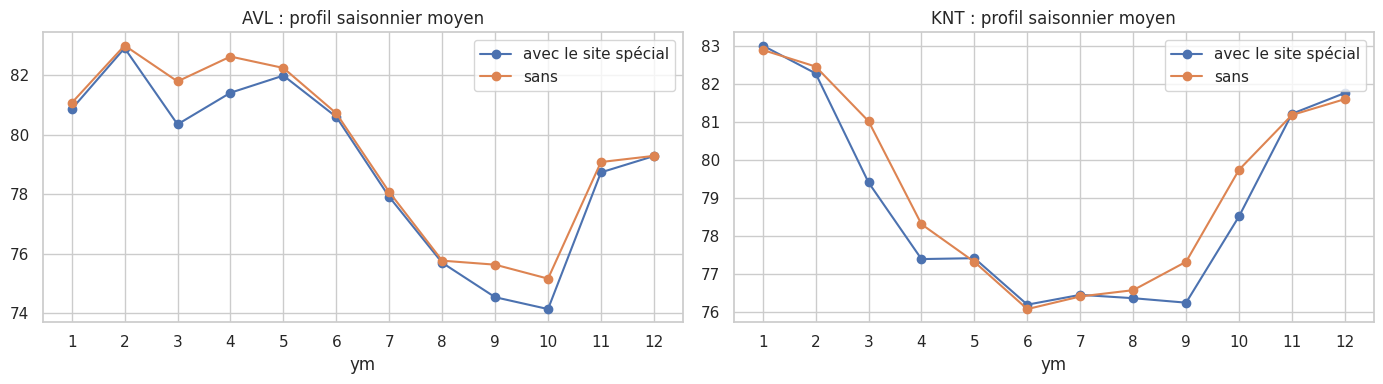

In [16]:
# Quel biais si on garde les 2 sites spéciaux dans les profils régionaux ? (fenêtres de panne : mars, avril, septembre, octobre)
rows = []
for z, special in [("AVL", "AVL-TRP"), ("KNT", "KNT-CHP")]:
    cols = [c for c in Q.columns if c.startswith(z)]
    full = Q[cols].groupby(Q.index.month).mean().mean(axis=1); clean = Q[[c for c in cols if c != special]].groupby(Q.index.month).mean().mean(axis=1)
    diff = (full - clean).round(2)
    rows.append((z, len(cols), diff[[3, 4, 9, 10]].mean().round(2), diff.drop([3, 4, 9, 10]).abs().mean().round(2)))
print(pd.DataFrame(rows, columns=["zone", "nb de sites", "biais moyen aux mois de panne (points)", "biais moyen aux autres mois (valeur absolue)"]).to_string(index=False))

# Effet sur la détection d'un cycle (ACF) de la moyenne régionale
def acf(x, k):
    x = np.asarray(x, float) - np.mean(x); return (x[:-k] * x[k:]).sum() / (x ** 2).sum()
for z, special in [("AVL", "AVL-TRP"), ("KNT", "KNT-CHP")]:
    cols = [c for c in Q.columns if c.startswith(z)]; a = Q[cols].mean(axis=1).values; b = Q[[c for c in cols if c != special]].mean(axis=1).values
    print(f"{z} : ACF(6) avec le site spécial = {acf(a, 6):+.2f} | sans = {acf(b, 6):+.2f} ;  ACF(12) avec = {acf(a, 12):+.2f} | sans = {acf(b, 12):+.2f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a_, (z, special) in zip(ax, [("AVL", "AVL-TRP"), ("KNT", "KNT-CHP")]):
    cols = [c for c in Q.columns if c.startswith(z)]
    Q[cols].groupby(Q.index.month).mean().mean(axis=1).plot(ax=a_, marker="o", label="avec le site spécial")
    Q[[c for c in cols if c != special]].groupby(Q.index.month).mean().mean(axis=1).plot(ax=a_, marker="o", label="sans")
    a_.set_title(f"{z} : profil saisonnier moyen"); a_.legend(); a_.set_xticks(range(1, 13))
plt.tight_layout(); plt.show()

### Interprétation (cellule 14)
toute analyse acoustique agrégée qui inclut ces deux sites est biaisée aux mois de mars, avril, septembre et octobre (≈ 1,2 point, soit environ 15 % de l'amplitude saisonnière de ≈ 8 points). Il faut les exclure ou les traiter séparément. C'est la conséquence pratique la plus importante du motif cyclique de panne du notebook 2.

## Cellule 15 — Export
 sauvegarder deux fichiers pour la synthèse finale (les originaux ne sont pas touchés) :
- panel_vergers_appareils.csv : le panel verger × mois avec les mesures d'appareil ;
- synthese_vergers_3_tables.csv : un profil par verger avec toutes les variables des trois tables.

In [17]:
out_panel = panel[["orchard_survey_id", "site_code", "survey_period", "flo", "fs", "pol", "yha", "res", "note", "uptime", "acoustic_quality", "maintenance_type", "fault", "provider", "device_model"]].copy()
out_panel.to_csv("panel_vergers_appareils.csv", index=False)
final = OF.join(sig[["fournisseur", "modèle"]]).reset_index()
final.to_csv("synthese_vergers_3_tables.csv", index=False)
print("Sauvegardé : panel_vergers_appareils.csv", out_panel.shape, "| synthese_vergers_3_tables.csv", final.shape)
try:
    from google.colab import files
    files.download("panel_vergers_appareils.csv"); files.download("synthese_vergers_3_tables.csv")
except ImportError:
    pass

Sauvegardé : panel_vergers_appareils.csv (1248, 15) | synthese_vergers_3_tables.csv (16, 17)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Synthèse du notebook 4

### Faits établis
1. **Les trois tables se joignent parfaitement** : 16 vergers × 78 mois, chacun avec son propre appareil.
2. **Les 8 premiers sites ont une origine distincte** : noms cohérents avec leur catégorie (4 cavernes, 3 vergers), alors que les 56 autres ont des noms générés **sans lien** avec la catégorie (Fisher p = 1,0). Renforce l'hypothèse « noyau de départ + sites générés » du notebook 1.
3. **Les mêmes trois vergers ressortent quand on réunit les tables** : AVL-TRP, TMB-BRC, AVL-FNQ, chacun pour une raison différente.
4. **Aucun lien dans le temps entre TMB-NAC et TMB-BRC** : |r| max 0,20 contre 0,35 au seuil de 5 % (p = 0,67), et les 15 autres vergers font autant. L'avantage de TMB-BRC est stable pendant que l'acoustique de TMB-NAC baisse de 84 à 76.
5. **Aucune relation entre une série d'appareil et une série de verger** sur 7 168 combinaisons (|r| max 0,46, identique au hasard : p = 0,38).
6. **Aucun choc régional** : corrélations entre sites voisins ≈ 0 (0,007), graphe de corrélation à seuil contrôlé **vide** ; le graphe naïf crée des communautés artificielles (ARI = 0,02 avec les régions).
7. **Le réseau spatial = 3 régions** (ARI = 1,0) ; aucun site exceptionnel n'est un pivot du réseau.
8. **Les deux sites à pannes cycliques biaisent de ≈ 1,2 point** les moyennes régionales aux mois de panne.

